In [4]:
import numpy as np
import pandas as pd

In [5]:
transaction_df = pd.read_csv("train_transaction.csv")

In [6]:
transaction_df.head()

,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,...,V330,V331,V332,V333,V334,V335,V336,V337,V338,V339
0,2987000,0,86400,68.5,W,13926,NaN,150.0,discover,142.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2987001,0,86401,29.0,W,2755,404.0,150.0,mastercard,102.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2987002,0,86469,59.0,W,4663,490.0,150.0,visa,166.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2987003,0,86499,50.0,W,18132,567.0,150.0,mastercard,117.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2987004,0,86506,50.0,H,4497,514.0,150.0,mastercard,102.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [7]:
transaction_df.shape

(590540, 394)

This dataset contains online e-commerce card transactions in which fraud has occurred

In [8]:
transaction_df.isnull().sum()

TransactionID          0
isFraud                0
TransactionDT          0
TransactionAmt         0
ProductCD              0
                   ...  
V335              508189
V336              508189
V337              508189
V338              508189
V339              508189
Length: 394, dtype: int64

In [9]:
transaction_df.duplicated()

0         False
1         False
2         False
3         False
4         False
          ...  
590535    False
590536    False
590537    False
590538    False
590539    False
Length: 590540, dtype: bool

In [10]:
#fraud distribution
transaction_df["isFraud"].value_counts()

isFraud
0    569877
1     20663
Name: count, dtype: int64

In [11]:
transaction_df["isFraud"].value_counts(normalize=True) * 100

isFraud
0    96.500999
1     3.499001
Name: proportion, dtype: float64

Fraud datasets are usually highly imbalanced

In [12]:
transaction_df.dtypes.value_counts()

float64    376
object      14
int64        4
Name: count, dtype: int64

In [13]:
missing = transaction_df.isnull().sum().sort_values(ascending=False)
missing.head(20)

dist2    552913
D7       551623
D13      528588
D14      528353
D12      525823
D6       517353
D9       515614
D8       515614
V153     508595
V139     508595
V162     508595
V161     508595
V154     508595
V138     508595
V158     508595
V157     508595
V163     508595
V156     508595
V155     508595
V149     508595
dtype: int64

In [14]:
transaction_df[["TransactionAmt", "TransactionDT"]].describe()

,TransactionAmt,TransactionDT
count,590540.000000,5.905400e+05
mean,135.027176,7.372311e+06
std,239.162522,4.617224e+06
min,0.251000,8.640000e+04
25%,43.321000,3.027058e+06
50%,68.769000,7.306528e+06
75%,125.000000,1.124662e+07
max,31937.391000,1.581113e+07


In [15]:
transaction_df.groupby("ProductCD")["isFraud"].agg(["count", "sum", "mean"]).sort_values("mean", ascending=False)

,count,sum,mean
ProductCD,,,
C,68519,8008,0.116873
S,11628,686,0.058996
H,33024,1574,0.047662
R,37699,1426,0.037826
W,439670,8969,0.020399


In [16]:
transaction_df.groupby("ProductCD")["isFraud"].mean() * 100

ProductCD
C    11.687269
H     4.766231
R     3.782594
S     5.899553
W     2.039939
Name: isFraud, dtype: float64

Fraud percentage for each product category

In [17]:
transaction_df.groupby("isFraud")["TransactionAmt"].describe()

,count,mean,std,min,25%,50%,75%,max
isFraud,,,,,,,,
0,569877.0,134.511665,239.395078,0.251,43.970,68.5,120.0,31937.391
1,20663.0,149.244779,232.212163,0.292,35.044,75.0,161.0,5191.000


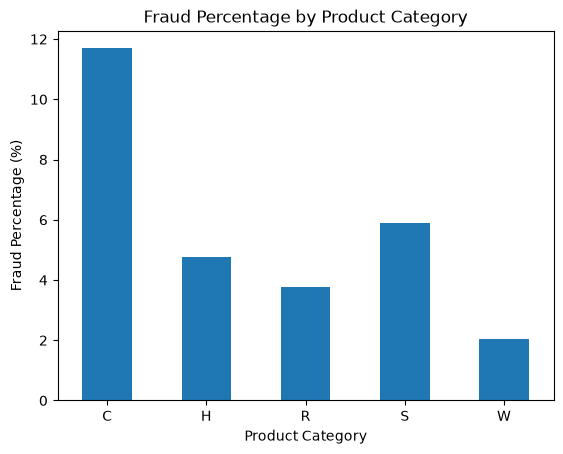

In [18]:
import matplotlib.pyplot as plt

fraud_by_product = (
    transaction_df.groupby("ProductCD")["isFraud"].mean() * 100
)
fraud_by_product.plot(kind="bar")

plt.title("Fraud Percentage by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Fraud Percentage (%)")
plt.xticks(rotation=0)
plt.show()

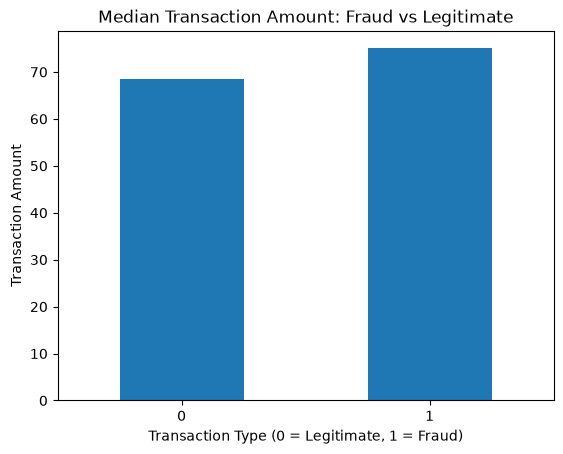

In [19]:
transaction_df.groupby("isFraud")["TransactionAmt"].median().plot(kind="bar")
plt.title("Median Transaction Amount: Fraud vs Legitimate")
plt.xlabel("Transaction Type (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Transaction Amount")
plt.xticks(rotation=0)
plt.show()

In [20]:
#missing values in each column
missing_percent = (transaction_df.isnull().mean() * 100).sort_values(ascending=False)
missing_percent.head(30)

dist2    93.628374
D7       93.409930
D13      89.509263
D14      89.469469
D12      89.041047
D6       87.606767
D9       87.312290
D8       87.312290
V153     86.123717
V139     86.123717
V162     86.123717
V161     86.123717
V154     86.123717
V138     86.123717
V158     86.123717
V157     86.123717
V163     86.123717
V156     86.123717
V155     86.123717
V149     86.123717
V148     86.123717
V147     86.123717
V146     86.123717
V142     86.123717
V141     86.123717
V140     86.123717
V151     86.122701
V152     86.122701
V145     86.122701
V144     86.122701
dtype: float64

In [21]:
missing_percent.describe()

count    394.000000
mean      41.073431
std       35.895976
min        0.000000
25%        0.214888
50%       28.612626
75%       77.913435
max       93.628374
dtype: float64

So a large portion of the dataset has substantial missing data

In [22]:
bins = [0, 10, 30, 50, 70, 90, 100]
labels = [
    "0-10%",
    "10-30%",
    "30-50%",
    "50-70%",
    "70-90%",
    "90-100%"
]
missing_groups = pd.cut(
    missing_percent,
    bins=bins,
    labels=labels,
    include_lowest=True
)
missing_groups.value_counts().sort_index()

0-10%      112
10-30%      90
30-50%      18
50-70%       6
70-90%     166
90-100%      2
Name: count, dtype: int64

202 out of 394 features have more than 70% missing values.

In [23]:
transaction_df.dtypes.to_frame("dtype").head(50)

,dtype
TransactionID,int64
isFraud,int64
TransactionDT,int64
TransactionAmt,float64
ProductCD,object
card1,int64
card2,float64
card3,float64
card4,object
card5,float64


In [24]:
transaction_df.select_dtypes(include="object").columns.tolist()

['ProductCD',
 'card4',
 'card6',
 'P_emaildomain',
 'R_emaildomain',
 'M1',
 'M2',
 'M3',
 'M4',
 'M5',
 'M6',
 'M7',
 'M8',
 'M9']

In [25]:
for col in transaction_df.select_dtypes(include="object").columns:
   print(col, "→", transaction_df[col].nunique(), "unique values")

ProductCD → 5 unique values
card4 → 4 unique values
card6 → 4 unique values
P_emaildomain → 59 unique values
R_emaildomain → 60 unique values
M1 → 2 unique values
M2 → 2 unique values
M3 → 2 unique values
M4 → 3 unique values
M5 → 2 unique values
M6 → 2 unique values
M7 → 2 unique values
M8 → 2 unique values
M9 → 2 unique values


In [26]:
unique_counts = transaction_df.nunique().sort_values()
unique_counts.head(30)

M5         2
V107       2
V1         2
V88        2
V65        2
V14        2
V305       2
M2         2
M1         2
M6         2
M7         2
M8         2
V41        2
M9         2
isFraud    2
M3         2
M4         3
V68        3
V89        3
V94        3
V12        4
V28        4
V27        4
card6      4
V35        4
V122       4
V121       4
V117       4
V118       4
card4      4
dtype: int64

In [27]:
#creating copy of original dataset
df = transaction_df.copy()

In [28]:
X = df.drop("isFraud", axis=1)
y = df["isFraud"]

In [29]:
#Remove TransactionID
X = X.drop("TransactionID", axis=1)

In [30]:
missing_threshold = 0.80
missing_ratio = X.isnull().mean()
cols_to_drop = missing_ratio[missing_ratio > missing_threshold].index
X = X.drop(columns=cols_to_drop)

print("Removed:", len(cols_to_drop))
print("Remaining features:", X.shape[1])

Removed: 55
Remaining features: 337


After setting up the threshold to 80% missingness => 55 columns were dropped and 337 are left to train model.

In [31]:
print(X.shape)
print(X.dtypes.value_counts())

(590540, 337)
float64    321
object      14
int64        2
Name: count, dtype: int64


In [32]:
X.isnull().sum().sum()

np.int64(67434214)

In [33]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,random_state=42, stratify=y)
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (472432, 337)
X_test: (118108, 337)
y_train: (472432,)
y_test: (118108,)


In [34]:
print("Training fraud distribution:")
print(y_train.value_counts())
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting fraud distribution:")
print(y_test.value_counts())
print(y_test.value_counts(normalize=True) * 100)

Training fraud distribution:
isFraud
0    455902
1     16530
Name: count, dtype: int64
isFraud
0    96.501084
1     3.498916
Name: proportion, dtype: float64

Testing fraud distribution:
isFraud
0    113975
1      4133
Name: count, dtype: int64
isFraud
0    96.50066
1     3.49934
Name: proportion, dtype: float64


In [35]:
# Checking object/categorical columns
categorical_cols = X_train.select_dtypes(include="object").columns.tolist()

print("Categorical columns:")
print(categorical_cols)
print("\nNumber of categorical columns:", len(categorical_cols))

for col in categorical_cols:
    print(col, "->", X_train[col].nunique(), "unique values")

Categorical columns:
['ProductCD', 'card4', 'card6', 'P_emaildomain', 'R_emaildomain', 'M1', 'M2', 'M3', 'M4', 'M5', 'M6', 'M7', 'M8', 'M9']

Number of categorical columns: 14
ProductCD -> 5 unique values
card4 -> 4 unique values
card6 -> 4 unique values
P_emaildomain -> 59 unique values
R_emaildomain -> 60 unique values
M1 -> 2 unique values
M2 -> 2 unique values
M3 -> 2 unique values
M4 -> 3 unique values
M5 -> 2 unique values
M6 -> 2 unique values
M7 -> 2 unique values
M8 -> 2 unique values
M9 -> 2 unique values


In [36]:
# One-hot encode categorical columns

X_train_encoded = pd.get_dummies(
    X_train,
    columns=categorical_cols,
    dummy_na=True
)
X_test_encoded = pd.get_dummies(
    X_test,
    columns=categorical_cols,
    dummy_na=True
)
X_train_encoded, X_test_encoded = X_train_encoded.align(
    X_test_encoded,
    join="left",
    axis=1,
    fill_value=0
)
print("X_train encoded:", X_train_encoded.shape)
print("X_test encoded:", X_test_encoded.shape)

X_train encoded: (472432, 488)
X_test encoded: (118108, 488)


In [37]:
# Checking remaining missing values after OHE
missing_after_threshold = X_train_encoded.isnull().mean().sort_values(ascending=False) * 100
print("Top 30 columns by remaining missing percentage:")
print(missing_after_threshold.head(30))

Top 30 columns by remaining missing percentage:
V243    77.852051
V231    77.852051
V246    77.852051
V244    77.852051
V242    77.852051
V241    77.852051
V240    77.852051
V236    77.852051
V235    77.852051
V233    77.852051
V232    77.852051
V230    77.852051
V248    77.852051
V229    77.852051
V228    77.852051
V226    77.852051
V225    77.852051
V224    77.852051
V223    77.852051
V219    77.852051
V218    77.852051
V217    77.852051
V247    77.852051
V237    77.852051
V249    77.852051
V265    77.852051
V278    77.852051
V277    77.852051
V276    77.852051
V252    77.852051
dtype: float64


In [38]:
categorical_cols = X_train.select_dtypes(include="object").columns.tolist()
print("Categorical columns:")
print(categorical_cols)
print("\nNumber of categorical columns:", len(categorical_cols))

Categorical columns:
['ProductCD', 'card4', 'card6', 'P_emaildomain', 'R_emaildomain', 'M1', 'M2', 'M3', 'M4', 'M5', 'M6', 'M7', 'M8', 'M9']

Number of categorical columns: 14


In [39]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

numerical_cols = X_train.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_cols = X_train.select_dtypes(include=["object"]).columns.tolist()

print("Numerical columns:", len(numerical_cols))
print("Categorical columns:", len(categorical_cols))

numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_cols),
        ("cat", categorical_transformer, categorical_cols)
    ]
)
print("Preprocessing pipeline created successfully.")

Numerical columns: 323
Categorical columns: 14
Preprocessing pipeline created successfully.


In [40]:
# Numerical-only baseline
numerical_features = [
    "TransactionAmt",
    "TransactionDT",
    "card1",
    "card2",
    "card3",
    "card5",
    "addr1",
    "addr2",
    "dist1",
    "dist2",
    "C1",
    "C2",
    "C3",
    "C4",
    "C5",
    "C6",
    "C7",
    "C8",
    "C9",
    "C10",
    "C11",
    "C12",
    "C13",
    "C14"
]
numerical_features = [
    col for col in numerical_features if col in X_train.columns
]
X_train_num = X_train[numerical_features].copy()
X_test_num = X_test[numerical_features].copy()
X_train_num = X_train_num.fillna(X_train_num.median())
X_test_num = X_test_num.fillna(X_train_num.median())

print("Features:", len(numerical_features))
print("Train:", X_train_num.shape)
print("Test:", X_test_num.shape)

Features: 23
Train: (472432, 23)
Test: (118108, 23)


In [41]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

lr_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)
lr_model.fit(X_train_num, y_train)
print("Logistic Regression training completed.")

Logistic Regression training completed.


/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [42]:
#Evaluation
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

y_pred = lr_model.predict(X_test_num)
y_prob = lr_model.predict_proba(X_test_num)[:, 1]
print("\nClassification Report:")
print(classification_report(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))


Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.65      0.78    113975
           1       0.06      0.58      0.10      4133

    accuracy                           0.64    118108
   macro avg       0.52      0.61      0.44    118108
weighted avg       0.94      0.64      0.75    118108

ROC-AUC: 0.6563362748812555


Accuracy isn't useful by itself here because the dataset is highly imbalanced

In [43]:
#Random Forest

from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)
rf_model.fit(X_train_num, y_train)
print("Random Forest training completed.")

Random Forest training completed.


In [44]:
#evaluation

from sklearn.metrics import classification_report, roc_auc_score
y_pred_rf = rf_model.predict(X_test_num)
y_prob_rf = rf_model.predict_proba(X_test_num)[:, 1]

print("Random Forest Classification Report:")
print(classification_report(y_test, y_pred_rf))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_rf))

Random Forest Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      0.99    113975
           1       0.88      0.69      0.78      4133

    accuracy                           0.99    118108
   macro avg       0.93      0.85      0.88    118108
weighted avg       0.99      0.99      0.99    118108

ROC-AUC: 0.9591230084022973


Random Forest is much better than Logistic Regression

In [45]:
#XGBoost baseline

from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)
xgb_model.fit(X_train_num, y_train)
print("XGBoost training completed.")

XGBoost training completed.


In [46]:
#evaluation

from sklearn.metrics import classification_report, roc_auc_score

y_pred_xgb = xgb_model.predict(X_test_num)
y_prob_xgb = xgb_model.predict_proba(X_test_num)[:, 1]
print("XGBoost Classification Report:")
print(classification_report(y_test, y_pred_xgb))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_xgb))

XGBoost Classification Report:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99    113975
           1       0.90      0.40      0.55      4133

    accuracy                           0.98    118108
   macro avg       0.94      0.70      0.77    118108
weighted avg       0.98      0.98      0.97    118108

ROC-AUC: 0.927589807150882


In [47]:
print("MODEL COMPARISON")
print("-----------------------------")
print("Logistic Regression ROC-AUC:", roc_auc_score(y_test, y_prob))
print("Random Forest ROC-AUC:", roc_auc_score(y_test, y_prob_rf))
print("XGBoost ROC-AUC:", roc_auc_score(y_test, y_prob_xgb))

MODEL COMPARISON
-----------------------------
Logistic Regression ROC-AUC: 0.6563362748812555
Random Forest ROC-AUC: 0.9591230084022973
XGBoost ROC-AUC: 0.927589807150882


Random Forest is the best of the three by ROC-AUC

In [48]:
print("Random Forest Classification Report:")
print(classification_report(y_test, y_pred_rf))

Random Forest Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      0.99    113975
           1       0.88      0.69      0.78      4133

    accuracy                           0.99    118108
   macro avg       0.93      0.85      0.88    118108
weighted avg       0.99      0.99      0.99    118108



In [49]:
#Confusion Matrix
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred_rf)
print("Random Forest Confusion Matrix:")
print(cm)

Random Forest Confusion Matrix:
[[113575    400]
 [  1262   2871]]


In [50]:
#Feature Importance

import pandas as pd
importance = pd.Series(
    rf_model.feature_importances_,
    index=X_train_num.columns
).sort_values(ascending=False)
print("Top 15 Important Features:")
print(importance.head(15))

Top 15 Important Features:
TransactionDT     0.105180
TransactionAmt    0.093111
card1             0.084625
C13               0.081041
card2             0.068685
addr1             0.062515
C5                0.059488
C14               0.048181
C1                0.044742
C2                0.039474
C8                0.037791
card5             0.037239
C6                0.032165
dist1             0.031710
C12               0.029821
dtype: float64


TransactionDT and TransactionAmt are among the strongest features, which is useful for later context/risk-factor analysis.

In [51]:
import os
print(os.getcwd())

/Users/sneha/Desktop/VeriPay


In [52]:
import pickle
with open("backend/models/ieee_cis_rf_model.pkl", "wb") as f:
    pickle.dump(rf_model, f)
print("Random Forest model saved successfully.")

Random Forest model saved successfully.


In [54]:
print(rf_model.feature_names_in_)

['TransactionAmt' 'TransactionDT' 'card1' 'card2' 'card3' 'card5' 'addr1'
 'addr2' 'dist1' 'C1' 'C2' 'C3' 'C4' 'C5' 'C6' 'C7' 'C8' 'C9' 'C10' 'C11'
 'C12' 'C13' 'C14']


In [55]:
features = rf_model.feature_names_in_
X_test_rf = X_test[features]
y_test_proba = rf_model.predict_proba(X_test_rf)[:, 1]
print(y_test_proba[:10])

[0.01 0.03 0.   0.02 0.   0.21 0.06 0.   0.   0.  ]


In [56]:
from sklearn.metrics import precision_recall_curve

precision, recall, thresholds = precision_recall_curve(
    y_test,
    y_test_proba
)
f1_scores = 2 * (precision * recall) / (precision + recall + 1e-10)
best_index = f1_scores.argmax()
print("Best threshold:", thresholds[best_index])
print("Precision:", precision[best_index])
print("Recall:", recall[best_index])
print("F1-score:", f1_scores[best_index])

Best threshold: 0.45
Precision: 0.8431760384289347
Recall: 0.7219937091700943
F1-score: 0.7778936391578075


In [57]:
from sklearn.metrics import confusion_matrix

y_test_pred_045 = (y_test_proba >= 0.45).astype(int)
cm = confusion_matrix(y_test, y_test_pred_045)
print(cm)

[[113420    555]
 [  1149   2984]]


In [58]:
tn, fp, fn, tp = cm.ravel()

fraud_detection_rate = tp / (tp + fn)
false_alarm_rate = fp / (fp + tn)
print("Fraud Detection Rate:", fraud_detection_rate)
print("False Alarm Rate:", false_alarm_rate)

Fraud Detection Rate: 0.7219937091700943
False Alarm Rate: 0.004869488923009432


In [59]:
import pandas as pd

feature_importance = pd.Series(
    rf_model.feature_importances_,
    index=rf_model.feature_names_in_
).sort_values(ascending=False)
print(feature_importance.head(10))

TransactionDT     0.105180
TransactionAmt    0.093111
card1             0.084625
C13               0.081041
card2             0.068685
addr1             0.062515
C5                0.059488
C14               0.048181
C1                0.044742
C2                0.039474
dtype: float64


In [60]:
import shap
print(shap.__version__)

0.52.0


In [61]:
import shap
explainer = shap.TreeExplainer(rf_model)
shap_values = explainer.shap_values(X_test_rf.iloc[:100])
print("SHAP values calculated successfully.")

SHAP values calculated successfully.


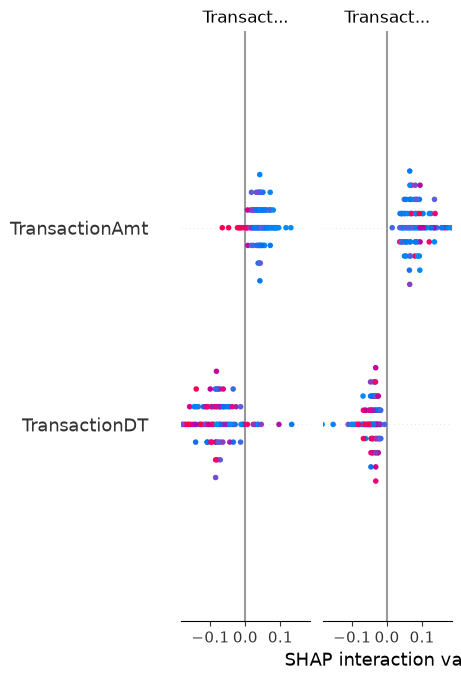

In [62]:
shap.summary_plot(
    shap_values,
    X_test_rf.iloc[:100],
    feature_names=rf_model.feature_names_in_
)

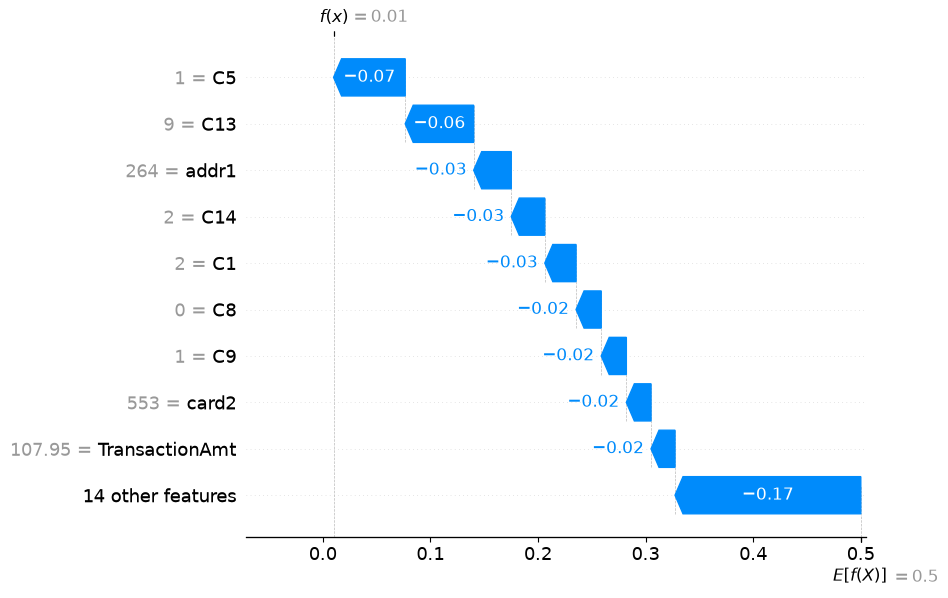

In [64]:
shap.plots.waterfall(
    shap.Explanation(
        values=shap_values[0, :, 1],
        base_values=explainer.expected_value[1],
        data=X_test_rf.iloc[0],
        feature_names=X_test_rf.columns
    )
)

In [65]:
import numpy as np

amount_median = X_train.groupby("card1")["TransactionAmt"].median()
X_test_context = X_test_rf.copy()
X_test_context["normal_amount"] = X_test_context["card1"].map(amount_median)
X_test_context["amount_deviation"] = (
    abs(X_test_context["TransactionAmt"] - X_test_context["normal_amount"])
    / (X_test_context["normal_amount"] + 1e-6)
)
print(X_test_context[[
    "card1",
    "TransactionAmt",
    "normal_amount",
    "amount_deviation"
]].head())

        card1  TransactionAmt  normal_amount  amount_deviation
316078   7585         107.950        107.950          0.000000
116888   3154          37.021         25.535          0.449814
410211  10057          59.000         59.000          0.000000
251027   6207          57.950         54.250          0.068203
191265  11207         107.950         77.000          0.401948
